# ManyIFEval probing results explorer

Reads only `results/` and `data/`; loads no LLM and trains nothing. CV (training-only) and TEST results are labelled separately everywhere. Regenerate with `python -c "from mife.probing import notebook; notebook.build()"`.

## 1. Setup and integrity check

In [1]:
import json, hashlib, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / 'src'))
from mife.probing import data, configs as C
R, T, D = ROOT / 'results', ROOT / 'results' / 'tables', ROOT / 'data'
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
def tab(name):
    p = T / f'{name}.csv'
    return pd.read_csv(p) if p.exists() else None
def pending(what):
    print(f'pending: {what}')
man = json.loads((R / 'run_manifest.json').read_text())
sha = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
paths = {'manifest_prompts': D/'manifest/prompts.parquet', 'manifest_prompt_rules': D/'manifest/prompt_rules.parquet',
         **{f'{m}_labels_prompt_rule': D/f'verification/{m}/main/labels_prompt_rule.parquet' for m in data.MODELS},
         **{f'{m}_labels_prompt': D/f'verification/{m}/main/labels_prompt.parquet' for m in data.MODELS},
         **{f'{m}_features_index': D/f'features/{m}/main/index.parquet' for m in data.MODELS}}
check = pd.DataFrame([{'file': k, 'matches_run_manifest': sha(p) == man['data_sha256'][k]} for k, p in paths.items()])
display(check)
assert check.matches_run_manifest.all(), 'data files differ from results/run_manifest.json'
print('test set unblinded:', data.test_unblinded())

,file,matches_run_manifest
0,manifest_prompts,True
1,manifest_prompt_rules,True
2,llama_labels_prompt_rule,True
3,qwen_labels_prompt_rule,True
4,llama_labels_prompt,True
5,qwen_labels_prompt,True
6,llama_features_index,True
7,qwen_features_index,True


test set unblinded: False


## 2. Dataset descriptives (TRAIN only)

Use the filters to slice the type × k × position rates.

In [2]:
tk = tab('desc_type_by_k_long'); bp = tab('desc_by_position'); fam = tab('desc_by_family')
display(tab('desc_by_k'))
try:
    import ipywidgets as W
    def show(model, type_id, k):
        d = tk[(tk.model == model)]
        if type_id != 'all': d = d[d.type_id == type_id]
        if k != 'all': d = d[d.k == int(k)]
        display(d[['type_id', 'k', 'est', 'lo', 'hi', 'n_groups']].round(4))
        if k != 'all':
            display(bp[(bp.model == model) & (bp.k == int(k))][['position', 'est', 'lo', 'hi']].round(4))
    W.interact(show, model=['llama', 'qwen'], type_id=['all'] + sorted(tk.type_id.unique()), k=['all', '1', '2', '3', '4', '5'])
except ImportError:
    display(tk.head(30))
display(fam)

,model,k,est,lo,hi,n_groups,sum_n
0,llama,1,0.165497,0.140010,0.190841,57,20520.0
1,llama,2,0.160892,0.139850,0.183346,57,82080.0
2,llama,3,0.165367,0.144632,0.187243,57,369360.0
3,llama,4,0.172084,0.151118,0.194548,57,984960.0
4,llama,5,0.181759,0.159012,0.206135,57,2052000.0
5,llama,all,0.176734,0.154967,0.199599,57,3508920.0
6,qwen,1,0.061745,0.046344,0.078265,57,20520.0
7,qwen,2,0.070870,0.055407,0.087078,57,82080.0
8,qwen,3,0.082126,0.065753,0.100125,57,369360.0
9,qwen,4,0.093148,0.075360,0.112482,57,984960.0


interactive(children=(Dropdown(description='model', options=('llama', 'qwen'), value='llama'), Dropdown(descri…

,model,task_family,est,lo,hi,n_groups,sum_n
0,llama,CREATIVE,0.189022,0.156349,0.222122,41,841320.0
1,llama,INFO,0.168879,0.139205,0.199057,28,574560.0
2,llama,PRACTICAL,0.200129,0.172079,0.229481,47,964440.0
3,llama,PERSUASIVE,0.151784,0.113550,0.192019,26,533520.0
4,llama,ANALYTICAL,0.148899,0.100493,0.200585,17,348840.0
5,llama,TRANSFORM,0.154946,0.100310,0.220752,12,246240.0
6,qwen,CREATIVE,0.112184,0.085140,0.139538,41,841320.0
7,qwen,INFO,0.102143,0.078250,0.126195,28,574560.0
8,qwen,PRACTICAL,0.090065,0.068590,0.112874,47,964440.0
9,qwen,PERSUASIVE,0.092028,0.060318,0.129589,26,533520.0


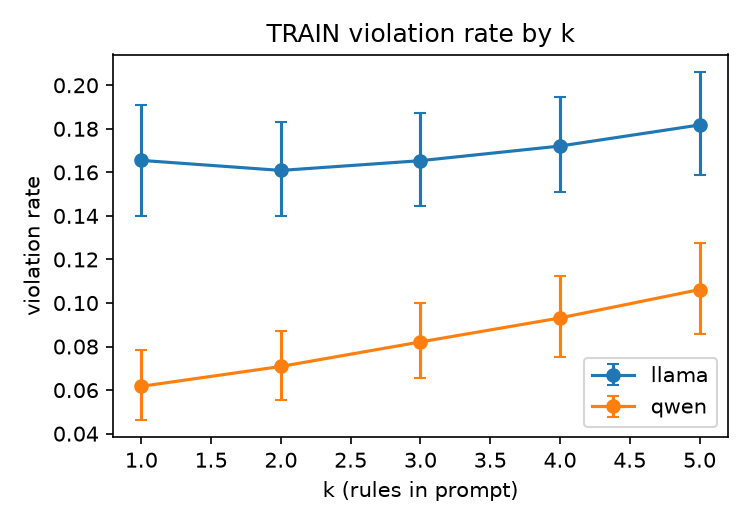

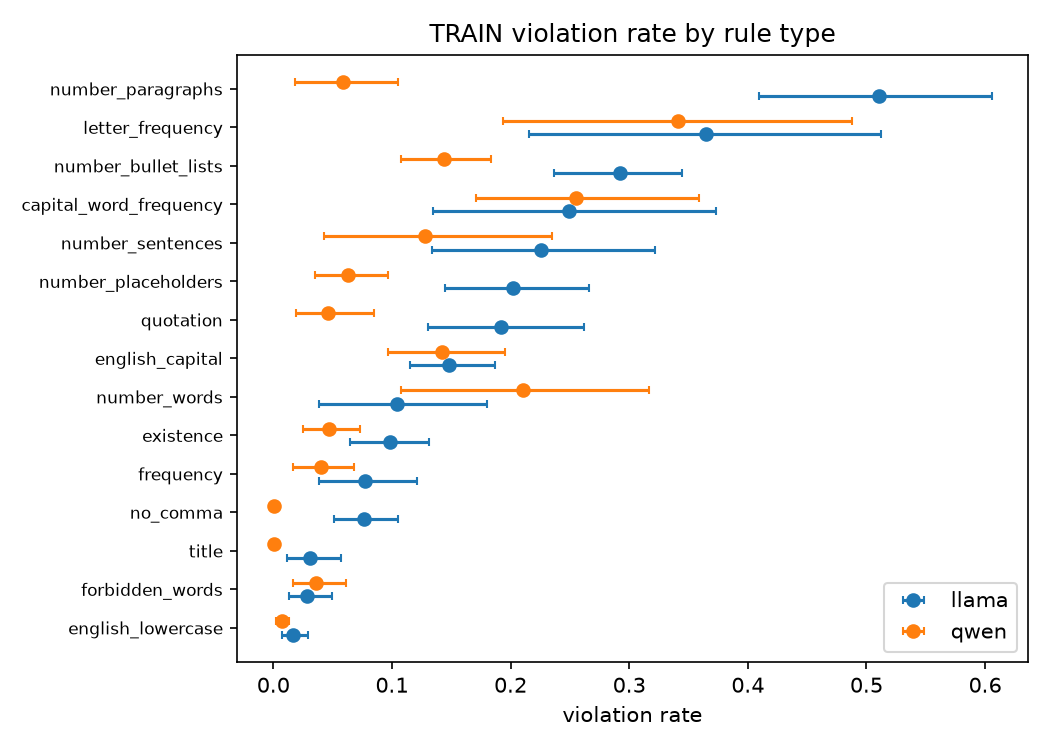

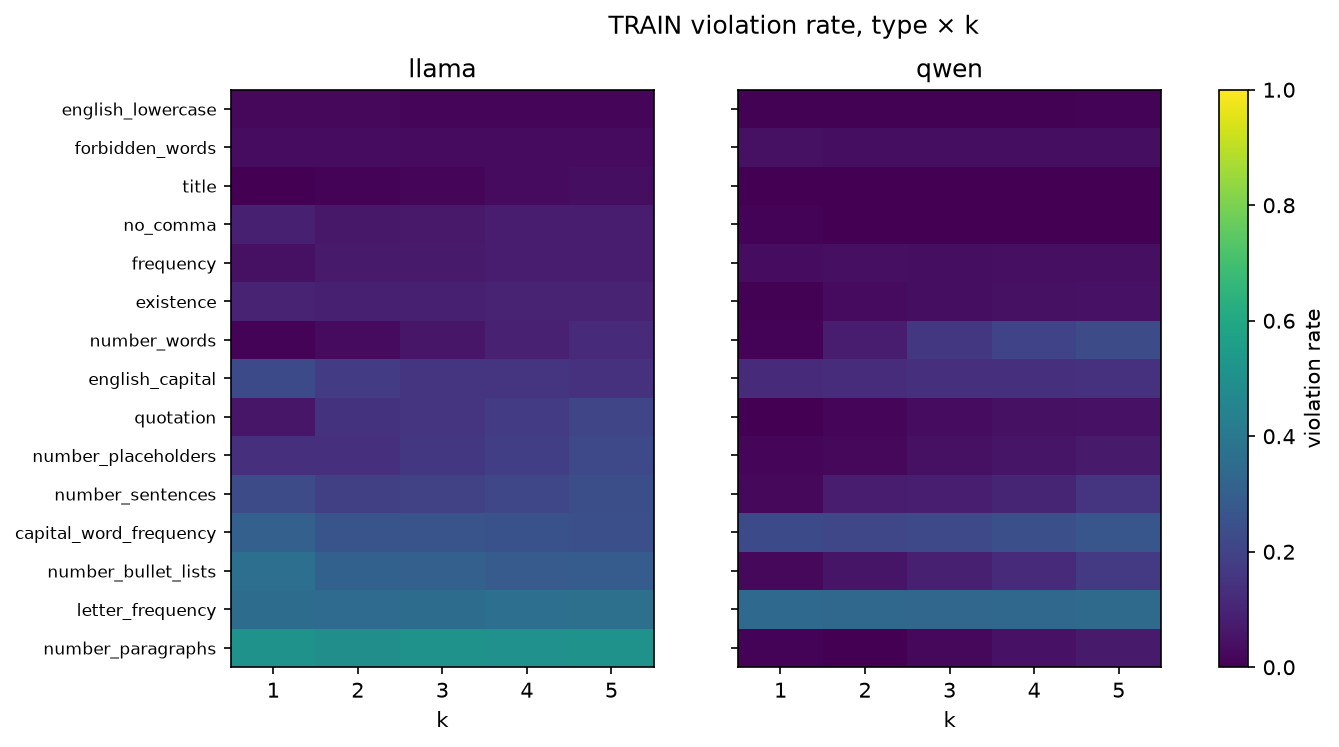

desc_label_distribution


,model,statistic,est,lo,hi
0,llama,share of prompt-rule rows with v = 0,0.531617,0.496575,0.565890
1,llama,share of prompt-rule rows with v = 20,0.053601,0.037430,0.070355
2,llama,mean p_hat,0.176734,0.154967,0.199599
3,llama,mean q_hat,0.175114,0.153898,0.197480
4,llama,share of prompts with q_hat = 0,0.104265,0.083345,0.124876
5,llama,q_hat quantile 0.1,0.000000,NaN,NaN
6,llama,q_hat quantile 0.25,0.050000,NaN,NaN
7,llama,q_hat quantile 0.5,0.150000,NaN,NaN
8,llama,q_hat quantile 0.75,0.262500,NaN,NaN
9,llama,q_hat quantile 0.9,0.380000,NaN,NaN


desc_truncation


,model,k,est,lo,hi,n_groups,sum_one
0,llama,1,0.000487,0.000097,0.001023,57,20520.0
1,llama,2,0.001145,0.000634,0.001730,57,41040.0
2,llama,3,0.001600,0.000942,0.002380,57,123120.0
3,llama,4,0.001714,0.001084,0.002429,57,246240.0
4,llama,5,0.002120,0.001321,0.003107,57,410400.0
5,llama,all,0.001838,0.001198,0.002591,57,841320.0
6,qwen,1,0.008431,0.004385,0.013791,57,20520.0
7,qwen,2,0.009503,0.004678,0.016522,57,41040.0
8,qwen,3,0.016366,0.007481,0.030947,57,123120.0
9,qwen,4,0.023047,0.011066,0.041506,57,246240.0


desc_english_capital


,model,statistic,est,lo,hi
0,llama,english_capital checks (response x rule),205200.000000,NaN,NaN
1,llama,violation rate (official checker),0.148475,0.114022,0.185573
2,llama,share of violations caused only by langdetect,0.042045,0.014787,0.082546
3,llama,violation rate if langdetect-only failures cou...,0.142232,0.106937,0.180288
4,qwen,english_capital checks (response x rule),205200.000000,NaN,NaN
5,qwen,violation rate (official checker),0.141798,0.097533,0.189206
6,qwen,share of violations caused only by langdetect,0.431453,0.193817,0.608953
7,qwen,violation rate if langdetect-only failures cou...,0.080619,0.058068,0.106327


desc_loops


,model,statistic,est,lo,hi,count
0,llama,loop share of all responses,0.000837,0.000425,0.001394,704
1,llama,loop share among truncated responses,0.443079,0.283382,0.596673,685
2,llama,truncated share among looping responses,0.973011,0.941172,0.992463,685
3,llama,looping responses (count),704.000000,NaN,NaN,704
4,qwen,loop share of all responses,0.020526,0.009563,0.035674,17269
5,qwen,loop share among truncated responses,0.722985,0.590615,0.827803,15161
6,qwen,truncated share among looping responses,0.877932,0.826380,0.929525,15161
7,qwen,looping responses (count),17269.000000,NaN,NaN,17269


In [3]:
for f in ['desc_by_k', 'desc_by_type', 'desc_type_by_k']:
    p = R / 'figures' / f'{f}.png'
    if p.exists():
        from IPython.display import Image; display(Image(str(p)))
for t in ['desc_label_distribution', 'desc_truncation', 'desc_english_capital', 'desc_loops']:
    print(t); display(tab(t))

## 3. Cross-validation (training-only): grid, selected layer and pooling, fold-to-fold variation

,model,objective,hidden_row,depth,best_cv_loss,selected
0,llama,1,16,50%,0.376125,True
1,llama,1,24,75%,0.397334,False
2,llama,1,33,100% (pre-norm),0.398207,False
3,llama,2,16,50%,0.016559,True
4,llama,2,24,75%,0.018716,False
5,llama,2,33,100% (pre-norm),0.018892,False
6,qwen,1,18,50%,0.261315,True
7,qwen,1,27,75%,0.264957,False
8,qwen,1,37,100% (pre-norm),0.274247,False
9,qwen,2,18,50%,0.011864,False


,model,objective,pooling,best_cv_loss,selected
0,llama,1,mean,0.333209,False
1,llama,1,sum,0.331574,True
2,llama,2,mean,0.017371,False
3,llama,2,sum,0.016930,True
4,qwen,1,mean,0.236666,False
5,qwen,1,sum,0.236058,True
6,qwen,2,mean,0.012840,False
7,qwen,2,sum,0.012740,True


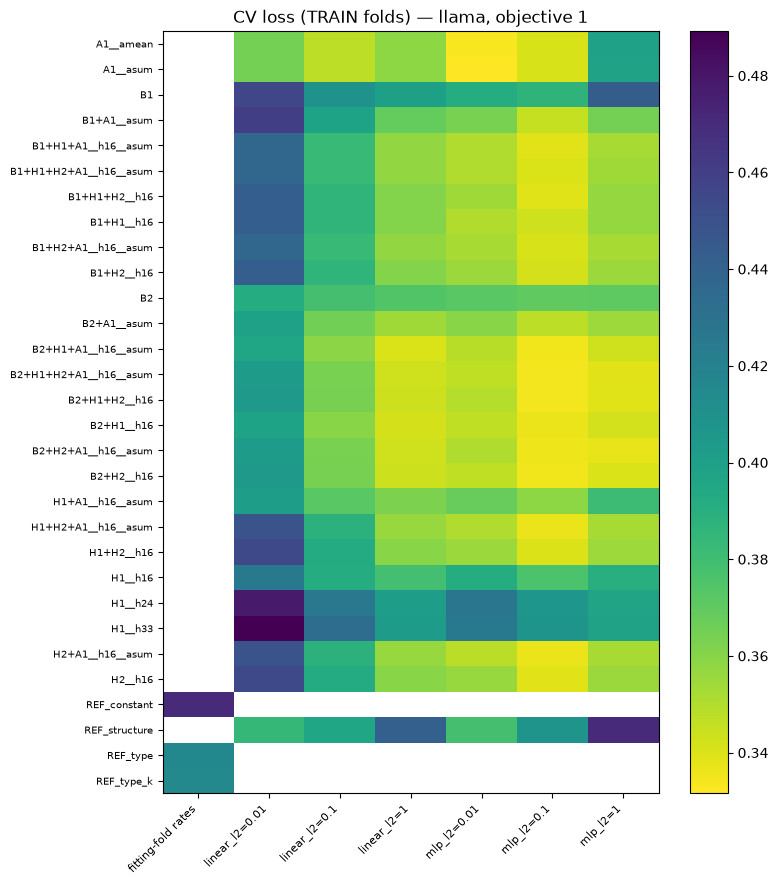

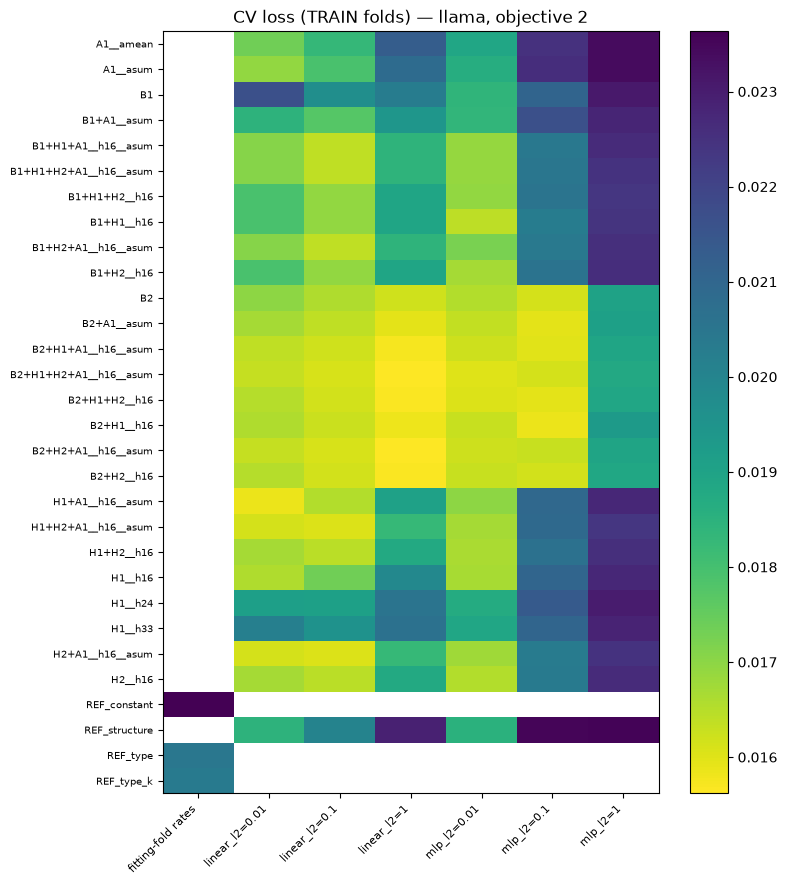

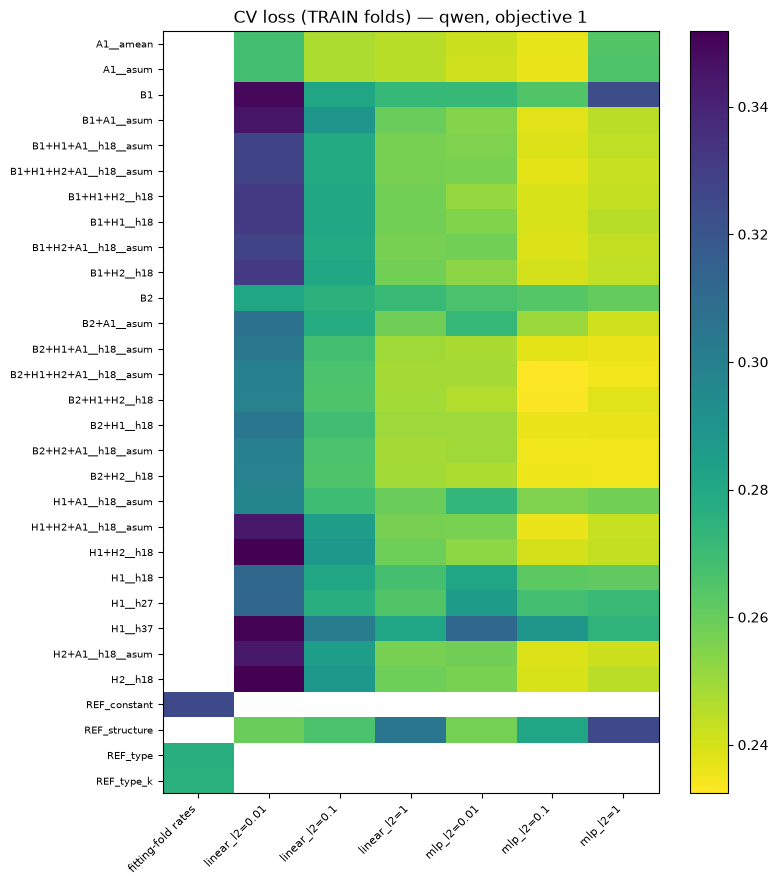

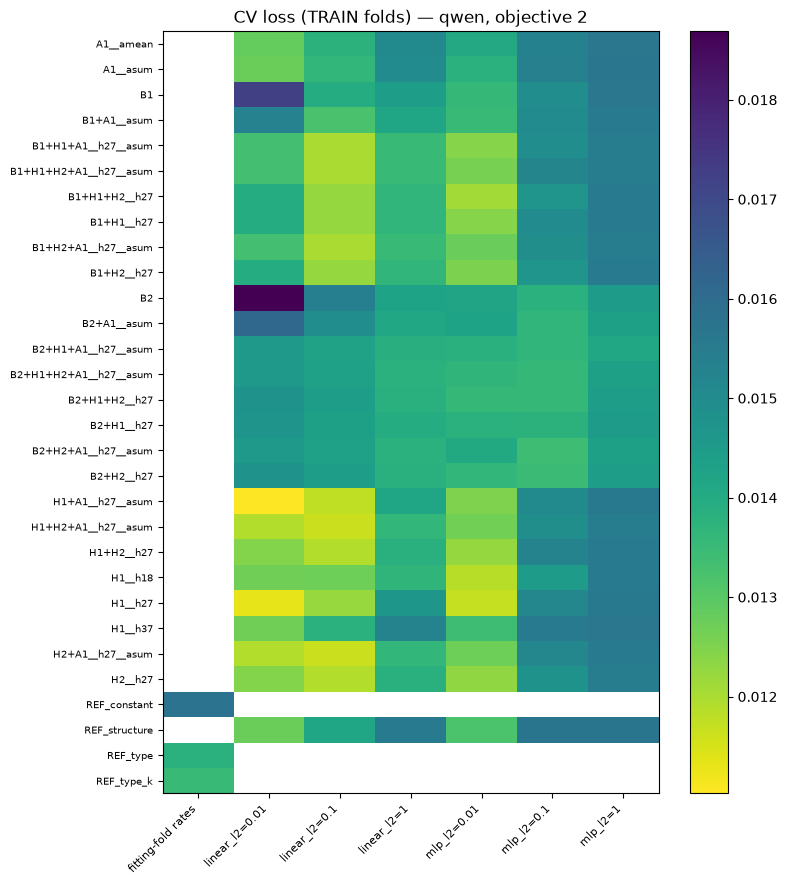

,model,objective,family,key,setting,epoch,cv_loss,fold_sd,minus_ref_structure
0,llama,1,reference,REF_constant,fitting-fold rates,NaN,0.470484,0.058594,0.092594
1,llama,1,reference,REF_type,fitting-fold rates,NaN,0.415505,0.042954,0.037615
2,llama,1,reference,REF_type_k,fitting-fold rates,NaN,0.415166,0.042767,0.037276
3,llama,1,reference,REF_structure,mlp_l2=0.01,10.0,0.377890,0.040946,0.000000
4,llama,1,probe-only,H1__h16,mlp_l2=0.1,23.0,0.376125,0.030009,-0.001765
...,...,...,...,...,...,...,...,...,...
103,qwen,2,B2 family,B2+A1__asum,mlp_l2=0.1,30.0,0.013652,0.001910,0.000903
104,qwen,2,B2 family,B2+H1+H2__h27,mlp_l2=0.1,22.0,0.013573,0.001645,0.000823
105,qwen,2,B2 family,B2+H1+A1__h27__asum,mlp_l2=0.1,17.0,0.013654,0.001751,0.000905
106,qwen,2,B2 family,B2+H2+A1__h27__asum,mlp_l2=0.1,15.0,0.013421,0.001297,0.000672


,model,objective,key,setting,edge
0,llama,1,A1__amean,mlp_l2=0.01,l2 at grid edge
1,llama,1,A1__asum,mlp_l2=0.01,l2 at grid edge
2,llama,1,B2,mlp_l2=0.1,MLP epoch 1 (schedule edge)
3,llama,1,H1__h24,mlp_l2=1,l2 at grid edge
4,llama,1,H1__h24,mlp_l2=1,MLP epoch 1 (schedule edge)
5,llama,1,H1__h33,mlp_l2=1,l2 at grid edge
6,llama,1,H1__h33,mlp_l2=1,MLP epoch 1 (schedule edge)
7,llama,1,REF_structure,mlp_l2=0.01,l2 at grid edge
8,llama,2,A1__amean,linear_l2=0.01,l2 at grid edge
9,llama,2,A1__asum,linear_l2=0.01,l2 at grid edge


,model,objective,adapt,lr,epochs,cv_loss,selected
0,llama,1,lora,0.0001,1,0.372357,True
1,llama,1,lora,0.0001,3,0.378403,False
2,llama,1,lora,0.0002,1,0.377066,False
3,llama,1,lora,0.0002,3,0.382012,False
4,llama,2,lora,0.0001,1,0.019257,False
5,llama,2,lora,0.0001,3,0.017026,False
6,llama,2,lora,0.0002,1,0.017874,False
7,llama,2,lora,0.0002,3,0.016475,True
8,qwen,1,lora,0.0001,1,0.268693,True
9,qwen,1,lora,0.0001,3,0.298037,False


In [4]:
g = tab('cv_grid_all'); sel = tab('cv_selected')
display(tab('cv_layer_selection')); display(tab('cv_pooling_selection'))
if g is not None:
    for (m, o), d in g.groupby(['model', 'objective']):
        pv = d.pivot_table(index='key', columns='setting', values='cv_loss')
        fig, ax = plt.subplots(figsize=(8, 0.28 * len(pv) + 1.5))
        im = ax.imshow(pv.values, aspect='auto', cmap='viridis_r')
        ax.set_yticks(range(len(pv))); ax.set_yticklabels(pv.index, fontsize=7)
        ax.set_xticks(range(len(pv.columns))); ax.set_xticklabels(pv.columns, rotation=45, ha='right', fontsize=8)
        ax.set_title(f'CV loss (TRAIN folds) — {m}, objective {o}'); fig.colorbar(im, ax=ax); plt.show()
if sel is not None:
    display(sel[['model', 'objective', 'family', 'key', 'setting', 'epoch', 'cv_loss', 'fold_sd', 'minus_ref_structure']])
display(tab('cv_boundary_hits')); display(tab('cv_b2_grid'))

## 4. Evaluation 1 leaderboard (TEST)

In [5]:
for o in (1, 2):
    t = tab(f'eval1_obj{o}')
    if t is None: pending(f'TEST evaluation, objective {o}'); continue
    for m, d in t.groupby('model'):
        print(m, 'objective', o); display(d.sort_values(d.columns[3]).reset_index(drop=True))
for name in ['eval1_obj1_by_type', 'eval1_obj1_by_k', 'eval1_obj2_by_k']:
    t = tab(name); display(t) if t is not None else pending(name)
for p in sorted((R / 'figures').glob('reliability_*.png')):
    from IPython.display import Image; display(Image(str(p)))

pending: TEST evaluation, objective 1
pending: TEST evaluation, objective 2
pending: eval1_obj1_by_type
pending: eval1_obj1_by_k
pending: eval1_obj2_by_k


## 5. Hypothesis contrasts (TEST): forest plots

In [6]:
c = tab('contrasts')
if c is None: pending('contrasts')
else:
    for (m, o), d in c.groupby(['model', 'objective']):
        d = d.reset_index(drop=True)
        fig, ax = plt.subplots(figsize=(7, 0.25 * len(d) + 1))
        ax.errorbar(d.est, range(len(d)), xerr=[d.est - d.lo, d.hi - d.est], fmt='o', capsize=2)
        ax.axvline(0, color='grey', lw=1); ax.set_yticks(range(len(d)))
        ax.set_yticklabels([f'{a} → {b}' for a, b in zip(d.a, d.b)], fontsize=7); ax.invert_yaxis()
        ax.set_title(f'{m}, objective {o}: metric(b) − metric(a) (negative favours b)'); plt.show()

pending: contrasts


## 6. Evaluation 2 (TEST): predicted vs observed differences

In [7]:
e = tab('eval2_summary')
if e is None: pending('Evaluation 2')
else:
    display(e)
    for p in sorted((R / 'figures').glob('eval2_*.png')):
        from IPython.display import Image; display(Image(str(p)))

pending: Evaluation 2


## 7. Error analysis

Largest residuals for a chosen configuration and where configurations disagree most. Uses TEST predictions after unblinding, otherwise TRAINING out-of-fold CV predictions (labelled).

In [8]:
def load_preds(model, obj):
    tdir = R / 'predictions' / model / f'obj{obj}' / 'test'
    if data.test_unblinded() and tdir.exists() and any(tdir.glob('*.parquet')):
        return 'TEST', pd.read_parquet(next(tdir.glob('*.parquet')))
    s = tab('cv_selected'); cols = {}
    if s is None: return None, None
    s = s[(s.model == model) & (s.objective == obj)]
    base = None
    for r in s.itertuples():
        p = R / 'predictions' / model / f'obj{obj}' / 'cv' / f'{r.key}.parquet'
        if not p.exists(): continue
        d = pd.read_parquet(p); key = [c for c in ('prompt_id', 'position', 'rule_id', 'type_id', 'fold') if c in d]
        base = d[key] if base is None else base
        cols[r.config] = d[r.setting].values
    if base is None:
        pending(f'CV predictions for {model} objective {obj}'); return None, None
    return 'CV (TRAIN, out-of-fold)', base.assign(**cols)
src, P1 = load_preds('llama', 1)
if P1 is not None:
    lab = data.labels_prompt_rule('llama', 'train')[['prompt_id', 'position', 'p_hat']]
    P1 = P1.merge(lab, on=['prompt_id', 'position'])
    cfg = [c for c in C.CONFIGS + C.REFERENCES if c in P1]
    focus = 'B1+H1+A1' if 'B1+H1+A1' in P1 else cfg[0]
    P1['residual'] = P1['p_hat'] - P1[focus]
    print(src, '— largest |residual| for', focus); display(P1.reindex(P1.residual.abs().sort_values(ascending=False).index).head(15))
    P1['disagreement'] = P1[cfg].std(axis=1)
    print('largest disagreement across configurations'); display(P1.sort_values('disagreement', ascending=False).head(15)[['prompt_id', 'type_id', 'p_hat', 'disagreement'] + cfg[:6]])

CV (TRAIN, out-of-fold) — largest |residual| for B1+H1+A1


,prompt_id,position,rule_id,type_id,fold,REF_constant,REF_type,REF_type_k,REF_structure,H1,H2,A1,H1+H2,H1+A1,H2+A1,...,B1+A1,B1+H1+H2,B1+H1+A1,B1+H2+A1,B1+H1+H2+A1,B2,B2+H1,B2+H2,B2+A1,B2+H1+H2,B2+H1+A1,B2+H2+A1,B2+H1+H2+A1,p_hat,residual
14274,g07-c4-k5-o14-t209,1,g07-r3,keywords:letter_frequency,1,0.195805,0.460002,0.464382,0.142649,0.238618,0.004245,0.016089,0.004789,0.062820,0.004243,...,0.002947,0.004521,0.002662,0.003967,0.004734,0.022444,0.013105,0.009686,0.019290,0.006555,0.003978,0.009596,0.007376,1.0,0.997338
12364,g07-c1-k3-o04-t209,2,g07-r3,keywords:letter_frequency,1,0.195805,0.460002,0.447994,0.076281,0.106214,0.004947,0.004421,0.005547,0.101816,0.001550,...,0.003036,0.010766,0.002932,0.002350,0.009677,0.016371,0.008834,0.004077,0.014101,0.006074,0.007228,0.001976,0.000982,1.0,0.997068
12454,g07-c1-k4-o06-t209,2,g07-r3,keywords:letter_frequency,1,0.195805,0.460002,0.457046,0.121513,0.096361,0.005694,0.001968,0.006831,0.095743,0.001855,...,0.003592,0.011835,0.003872,0.003433,0.007867,0.023722,0.010560,0.005218,0.015754,0.007388,0.007698,0.002466,0.001645,1.0,0.996128
14350,g07-c4-k5-o19-t209,2,g07-r3,keywords:letter_frequency,1,0.195805,0.460002,0.464382,0.151964,0.233073,0.005374,0.028526,0.005889,0.083112,0.005926,...,0.003939,0.005839,0.004055,0.005300,0.005998,0.025341,0.014826,0.011731,0.020686,0.007374,0.005008,0.012166,0.009272,1.0,0.995945
12646,g07-c1-k5-o08-t209,2,g07-r3,keywords:letter_frequency,1,0.195805,0.460002,0.464382,0.097317,0.094978,0.005913,0.001559,0.006177,0.083744,0.002287,...,0.003675,0.012296,0.004474,0.003805,0.006538,0.023893,0.011159,0.005385,0.017686,0.007933,0.007063,0.002676,0.002352,1.0,0.995526
12431,g07-c1-k4-o04-t209,3,g07-r3,keywords:letter_frequency,1,0.195805,0.460002,0.457046,0.127228,0.090980,0.006049,0.003382,0.006776,0.110624,0.002255,...,0.004721,0.013080,0.004837,0.003862,0.010142,0.024430,0.011053,0.005301,0.019487,0.007633,0.009531,0.002893,0.001909,1.0,0.995163
12662,g07-c1-k5-o09-t209,3,g07-r3,keywords:letter_frequency,1,0.195805,0.460002,0.464382,0.101393,0.109894,0.006418,0.001758,0.006749,0.091771,0.002540,...,0.004099,0.014917,0.004985,0.004057,0.007626,0.026575,0.011851,0.005745,0.019158,0.008603,0.007728,0.003057,0.002711,1.0,0.995015
12374,g07-c1-k3-o05-t209,3,g07-r3,keywords:letter_frequency,1,0.195805,0.460002,0.447994,0.090789,0.113451,0.005655,0.030385,0.006371,0.121213,0.002517,...,0.006073,0.013238,0.005936,0.002718,0.020711,0.016398,0.009850,0.004564,0.030902,0.007064,0.013556,0.003841,0.001569,1.0,0.994064
12356,g07-c1-k3-o03-t209,3,g07-r3,keywords:letter_frequency,1,0.195805,0.460002,0.447994,0.090789,0.109759,0.005573,0.035084,0.005903,0.128562,0.002650,...,0.006478,0.013143,0.006330,0.002839,0.020508,0.016942,0.009496,0.004322,0.029621,0.006523,0.013574,0.003582,0.001506,1.0,0.993670
14337,g07-c4-k5-o18-t209,4,g07-r3,keywords:letter_frequency,1,0.195805,0.460002,0.464382,0.162615,0.327923,0.006328,0.021163,0.007754,0.098808,0.008004,...,0.006705,0.008240,0.006558,0.008502,0.010574,0.023681,0.018237,0.014030,0.026224,0.009666,0.006813,0.020174,0.017687,1.0,0.993442


largest disagreement across configurations


,prompt_id,type_id,p_hat,disagreement,H1,H2,A1,H1+H2,H1+A1,H2+A1
46696,g22-c2-k2-o01-t3478,keywords:letter_frequency,0.00,0.399361,0.125876,0.944988,0.384476,0.957401,0.326080,0.930028
46691,g22-c2-k2-o00-t3478,keywords:letter_frequency,0.00,0.397969,0.164006,0.929370,0.535119,0.944675,0.258047,0.948786
48507,g22-c5-k5-o04-t3478,keywords:letter_frequency,0.00,0.396701,0.039307,0.885369,0.854498,0.909968,0.083924,0.897247
48826,g22-c6-k4-o01-t3478,keywords:letter_frequency,0.00,0.396456,0.087509,0.909841,0.691711,0.916113,0.142997,0.921225
48642,g22-c5-k5-o13-t3478,keywords:letter_frequency,0.00,0.395987,0.115673,0.904782,0.790820,0.917064,0.136197,0.907648
48611,g22-c5-k5-o11-t3478,keywords:letter_frequency,0.00,0.395407,0.068598,0.914129,0.889263,0.900249,0.120486,0.904396
46955,g22-c2-k5-o03-t3478,keywords:letter_frequency,0.00,0.395207,0.198958,0.885793,0.859386,0.910257,0.312556,0.950494
48551,g22-c5-k5-o07-t3478,keywords:letter_frequency,0.00,0.394705,0.032576,0.893507,0.806174,0.906092,0.098345,0.883844
47090,g22-c2-k5-o12-t3478,keywords:letter_frequency,0.00,0.394626,0.114263,0.868475,0.897312,0.896292,0.288547,0.947751
48920,g22-c6-k4-o09-t3478,keywords:letter_frequency,0.00,0.394582,0.103551,0.923660,0.229855,0.927877,0.117114,0.877682


## 8. Prompt drill-down

Pick a `prompt_id` (TRAIN prompts; TEST prompts only after unblinding).

In [9]:
split = 'all' if data.test_unblinded() else 'train'
Pm = data.prompts(split); PRm = data.prompt_rules(split)
def drill(prompt_id):
    p = Pm.set_index('prompt_id').loc[prompt_id]
    print(f'{prompt_id}  split={p.split}  task_family={p.task_family}  k={p.k}\n'); print(p.prompt_text, '\n')
    rules = PRm[PRm.prompt_id == prompt_id][['position', 'rule_id', 'type_id', 'kwargs_json', 'rule_text']]
    for m in data.MODELS:
        L = data.labels_prompt_rule(m, p.split)
        rules = rules.merge(L[L.prompt_id == prompt_id][['position', 'p_hat']].rename(columns={'p_hat': f'p_hat_{m}'}), on='position')
        q = data.labels_prompt(m, p.split); print(m, 'q_hat =', float(q[q.prompt_id == prompt_id].q_hat.iloc[0]))
    display(rules)
    for m in data.MODELS:
        s, Pp = load_preds(m, 1)
        if Pp is not None and prompt_id in set(Pp.prompt_id):
            print(m, s, 'predictions'); display(Pp[Pp.prompt_id == prompt_id].drop(columns=[c for c in ('fold',) if c in Pp]).round(3))
    g = data.generations('llama', p.split, columns=['sample_index', 'response_text']).query('prompt_id == @prompt_id').sort_values('sample_index').head(3)
    V = data.verification('llama', 'verification_long.parquet', p.split, columns=['response_id', 'position', 'violated'])
    for r in g.itertuples():
        v = V[V.response_id == r.response_id].sort_values('position')
        print(f'--- llama sample {r.sample_index}: violated by position', dict(zip(v.position, v.violated)))
        print(r.response_text[:1200])
example = Pm.prompt_id.iloc[1234]
try:
    import ipywidgets as W
    W.interact(drill, prompt_id=W.Text(value=example))
except ImportError:
    drill(example)
drill(example)

interactive(children=(Text(value='g04-c5-k2-o00-t1216', description='prompt_id'), Output()), _dom_classes=('wi…

g04-c5-k2-o00-t1216  split=train  task_family=INFO  k=2

What sentiments existed in the Croatian and Serbian nations towards the Austrian Empire at the end of the 19th century?

Your response should follow the instructions below:
- In your response, words with all capital letters should appear less than 15 times.
- Your answer must contain a title, wrapped in double angular brackets, such as <<poem of joy>>. 



llama q_hat = 0.025


qwen q_hat = 0.0


,position,rule_id,type_id,kwargs_json,rule_text,p_hat_llama,p_hat_qwen
0,1,g04-r1,change_case:capital_word_frequency,"{""capital_frequency"": 15, ""capital_relation"": ...","In your response, words with all capital lette...",0.05,0.0
1,2,g04-r4,detectable_format:title,{},"Your answer must contain a title, wrapped in d...",0.00,0.0


llama CV (TRAIN, out-of-fold) predictions


,prompt_id,position,rule_id,type_id,REF_constant,REF_type,REF_type_k,REF_structure,H1,H2,A1,H1+H2,H1+A1,H2+A1,H1+H2+A1,...,B1+H1,B1+H2,B1+A1,B1+H1+H2,B1+H1+A1,B1+H2+A1,B1+H1+H2+A1,B2,B2+H1,B2+H2,B2+A1,B2+H1+H2,B2+H1+A1,B2+H2+A1,B2+H1+H2+A1
5135,g04-c5-k2-o00-t1216,1,g04-r1,change_case:capital_word_frequency,0.171,0.266,0.269,0.377,0.244,0.517,0.085,0.445,0.180,0.445,0.174,...,0.392,0.516,0.177,0.574,0.309,0.507,0.376,0.102,0.057,0.111,0.183,0.165,0.075,0.062,0.136
5136,g04-c5-k2-o00-t1216,2,g04-r4,detectable_format:title,0.171,0.038,0.011,0.050,0.010,0.011,0.002,0.007,0.006,0.003,0.006,...,0.014,0.007,0.015,0.010,0.006,0.011,0.008,0.046,0.012,0.015,0.010,0.011,0.007,0.010,0.017


qwen CV (TRAIN, out-of-fold) predictions


,prompt_id,position,rule_id,type_id,REF_constant,REF_type,REF_type_k,REF_structure,H1,H2,A1,H1+H2,H1+A1,H2+A1,H1+H2+A1,...,B1+H1,B1+H2,B1+A1,B1+H1+H2,B1+H1+A1,B1+H2+A1,B1+H1+H2+A1,B2,B2+H1,B2+H2,B2+A1,B2+H1+H2,B2+H1+A1,B2+H2+A1,B2+H1+H2+A1
5135,g04-c5-k2-o00-t1216,1,g04-r1,change_case:capital_word_frequency,0.092,0.268,0.221,0.198,0.346,0.378,0.241,0.395,0.528,0.148,0.126,...,0.3,0.384,0.232,0.168,0.525,0.246,0.311,0.285,0.304,0.333,0.348,0.325,0.263,0.192,0.154
5136,g04-c5-k2-o00-t1216,2,g04-r4,detectable_format:title,0.092,0.000,0.000,0.004,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.045,0.000,0.000,0.000,0.000,0.000,0.000,0.000


--- llama sample 0: violated by position {1: 0, 2: 0}
<<National Sentiments in the Balkans>>

At the end of the 19th century, the Croatian and Serbian nations had complex and often conflicting relationships with the Austrian Empire. 

Croatians generally viewed the Austrian Empire as a patron and a protector, as it provided them with a degree of autonomy and self-governance through the Croatian Parliament, also known as the Sabor. However, many Croatians also felt a sense of cultural and national identity that was distinct from the Austrians, and they sought greater independence and unity with other South Slavic peoples.

On the other hand, many Serbs saw the Austrian Empire as an oppressive force that had suppressed their national aspirations and prevented them from achieving unity with other Serbs in the Balkans. The Serbian National Revival movement, which emerged in the mid-19th century, emphasized the importance of Serbian language, culture, and history, and sought to promote Serb

## 9. Llama vs Qwen

In [10]:
display(tab('desc_cross_model_type')); display(tab('desc_cross_model_corr'))
s = tab('cv_selected')
if s is not None:
    w = s.pivot_table(index=['objective', 'config'], columns='model', values='cv_loss')
    display(w)
e = tab('eval1_obj1')
if e is not None:
    display(e.pivot_table(index='config', columns='model', values=e.columns[3]))
else:
    pending('TEST comparison')

,type_id,llama,qwen,llama_minus_qwen,diff_lo,diff_hi
0,change_case:english_lowercase,0.016164,0.007220,0.008944,-0.000302,0.022320
1,detectable_format:title,0.031265,0.000365,0.030900,0.011344,0.057042
2,keywords:forbidden_words,0.028551,0.035849,-0.007297,-0.015953,-0.000396
3,keywords:frequency,0.076940,0.040478,0.036462,0.016401,0.061183
4,keywords:letter_frequency,0.364955,0.340835,0.024120,0.001867,0.048982
5,length_constraints:number_paragraphs,0.510717,0.058674,0.452042,0.367099,0.533418
6,change_case:capital_word_frequency,0.249318,0.255465,-0.006147,-0.093611,0.083357
7,punctuation:no_comma,0.076719,0.000841,0.075877,0.050756,0.103753
8,keywords:existence,0.098075,0.047113,0.050962,0.012816,0.092399
9,startend:quotation,0.192191,0.045996,0.146195,0.087794,0.208160


,statistic,est,lo,hi,n_prompts
0,Spearman rho of q_hat (per prompt),0.434309,0.358196,0.505645,42066


model                       llama      qwen
objective config                           
1         A1             0.331574  0.236058
          B1             0.386822  0.264620
          B1+A1          0.345144  0.237940
          B1+H1          0.342923  0.239634
          B1+H1+A1       0.338959  0.238669
          B1+H1+H2       0.339323  0.239483
          B1+H1+H2+A1    0.340695  0.237424
          B1+H2          0.341523  0.240142
          B1+H2+A1       0.340981  0.238730
          B2             0.370031  0.260571
          B2+A1          0.347240  0.240878
          B2+H1          0.336471  0.235949
          B2+H1+A1       0.334962  0.235815
          B2+H1+H2       0.334514  0.233075
          B2+H1+H2+A1    0.334062  0.232378
          B2+H2          0.334676  0.234909
          B2+H2+A1       0.335319  0.234773
          H1             0.376125  0.261315
          H1+A1          0.358311  0.255552
          H1+H2          0.339606  0.240270
          H1+H2+A1       0.336277  0.235784
          H2             0.338952  0.239646
          H2+A1          0.336444  0.238635
          REF_constant   0.470484  0.325571
          REF_structure  0.377890  0.257340
          REF_type       0.415505  0.276458
          REF_type_k     0.415166  0.275631
2         A1             0.016930  0.012740
          B1             0.018383  0.013600
          B1+A1          0.017738  0.013226
          B1+H1          0.016420  0.012245
          B1+H1+A1       0.016384  0.011992
          B1+H1+H2       0.016912  0.012089
          B1+H1+H2+A1    0.016384  0.011992
          B1+H2          0.016687  0.012245
          B1+H2+A1       0.016384  0.011992
          B2             0.016126  0.013788
          B2+A1          0.015944  0.013652
          B2+H1          0.015828  0.013752
          B2+H1+A1       0.015728  0.013654
          B2+H1+H2       0.015655  0.013573
          B2+H1+H2+A1    0.015619  0.013572
          B2+H2          0.015655  0.013481
          B2+H2+A1       0.015619  0.013421
          H1             0.016559  0.011297
          H1+A1          0.015847  0.011027
          H1+H2          0.016434  0.011917
          H1+H2+A1       0.016026  0.011644
          H2             0.016434  0.011917
          H2+A1          0.016026  0.011644
          REF_constant   0.023636  0.015768
          REF_structure  0.018467  0.012749
          REF_type       0.020456  0.013788
          REF_type_k     0.020362  0.013499

pending: TEST comparison
